# 03 — Exploratory Data Analysis

Input: `philly311_clean.csv` from notebook 02.

Goal: understand the data well enough to make informed choices in modeling (the fast/slow
threshold, which features look promising, whether the log transform was warranted).
Every chart here should end with a one-line takeaway you can reuse in your report.

In [3]:
from google.colab import files
uploaded = files.upload()  # choose philly311_clean.csv from your computer

Saving philly311_clean.csv to philly311_clean.csv
Saving philly311_still_open.csv to philly311_still_open (1).csv


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

TYPE_COL = "service_name"       # keep consistent with notebook 02's CONFIG
ZIP_COL = "zipcode"
AGENCY_COL = "agency_responsible"

df = pd.read_csv("philly311_clean.csv", parse_dates=["requested_datetime", "closed_datetime"])
df.describe(include="all").T

/tmp/ipykernel_2299/2271690210.py:12: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("philly311_clean.csv", parse_dates=["requested_datetime", "closed_datetime"])


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
the_geom,251867,173405,0101000020E61000000FC4BBF7B4C652C0A3F8F6765706...,122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cartodb_id,252419.0,NaN,NaN,NaN,2950096.074749,1508.0,1755999.5,3070982.0,4214117.0,5907215.0,1498094.454793
the_geom_webmercator,251867,173253,0101000020110F000078D411E5ACE45FC13F407E21EE96...,122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
objectid,252419.0,NaN,NaN,NaN,2950081.216521,1489.0,1755998.5,3070947.0,4214104.0,5907215.0,1498096.015087
service_request_id,252419.0,NaN,NaN,NaN,14170325.610604,10038990.0,12403437.0,14185785.0,15962203.0,19899390.0,2145847.131135
status,252419,1,Closed,252419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status_notes,179167,9,Information Provided,135397,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_name,252419,1,Abandoned Vehicle,252419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_code,252419,1,SR-PD01,252419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
agency_responsible,252419,2,Police Department,252416,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Distribution of resolution time

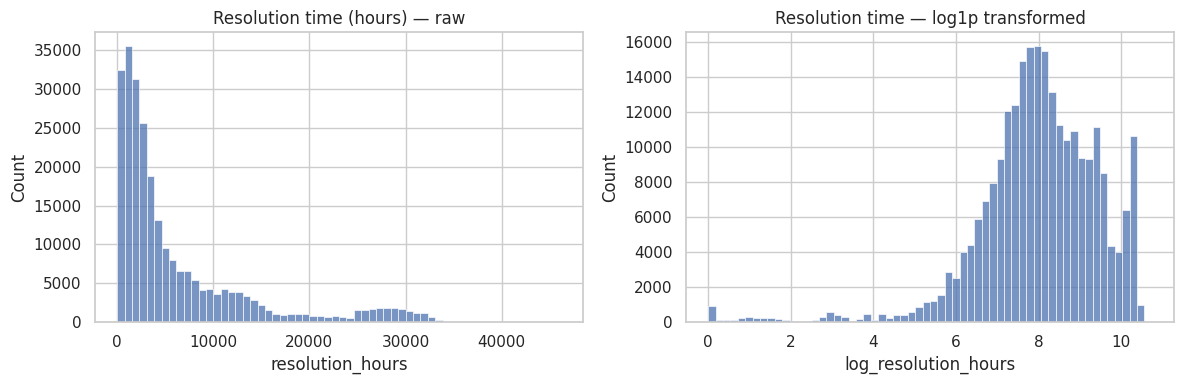

count    252419.000000
mean       6254.732557
std        7539.764354
min           0.000000
25%        1439.295417
50%        3134.665556
75%        7905.640278
max       46153.265000
Name: resolution_hours, dtype: float64

Median (hours): 3134.665555555556
Median (days): 130.61106481481482


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["resolution_hours"], bins=60, ax=axes[0])
axes[0].set_title("Resolution time (hours) — raw")
sns.histplot(df["log_resolution_hours"], bins=60, ax=axes[1])
axes[1].set_title("Resolution time — log1p transformed")
plt.tight_layout()
plt.show()

print(df["resolution_hours"].describe())
print("\nMedian (hours):", df["resolution_hours"].median())
print("Median (days):", df["resolution_hours"].median() / 24)

In [12]:
df[df["log_resolution_hours"] > 10]["resolution_hours"].describe()
df[df["log_resolution_hours"] > 10]["status_notes"].value_counts()

,count
status_notes,
Information Provided,426
Issue Resolved,26
Other,10
Referred to another organization,1


*Note the median above — you'll use it (or another cutoff you justify) for the
classification threshold in notebook 04.*

## 2. Resolution time by day of week / weekend

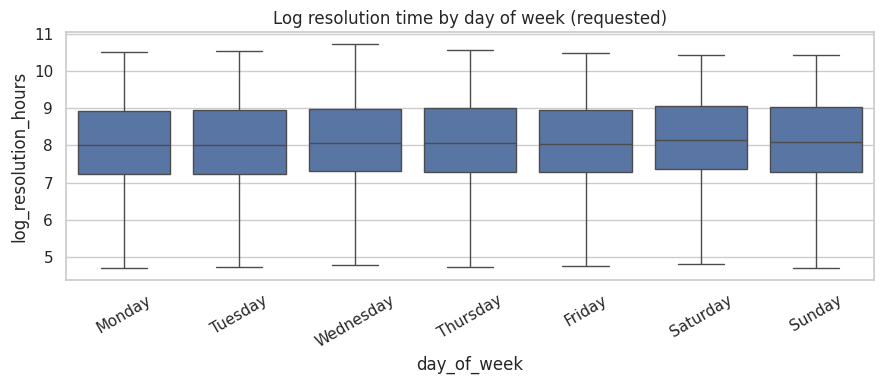

In [6]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="day_of_week", y="log_resolution_hours", order=order, showfliers=False)
plt.title("Log resolution time by day of week (requested)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 3. Resolution time by responsible agency

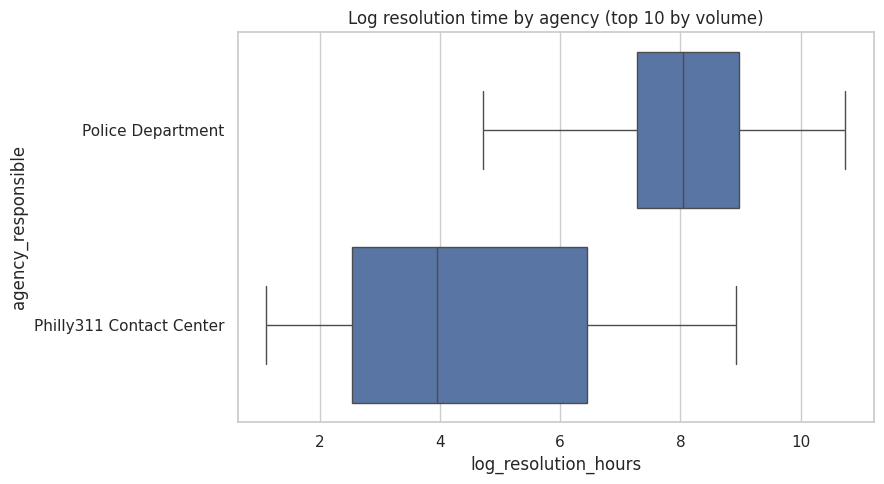

In [7]:
top_agencies = df[AGENCY_COL].value_counts().head(10).index
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df[df[AGENCY_COL].isin(top_agencies)],
    y=AGENCY_COL, x="log_resolution_hours", showfliers=False
)
plt.title("Log resolution time by agency (top 10 by volume)")
plt.tight_layout()
plt.show()

## 4. Resolution time by location (zip code)

In [8]:
zip_summary = (
    df.groupby(ZIP_COL)["resolution_hours"]
    .agg(["median", "count"])
    .query("count >= 30")
    .sort_values("median", ascending=False)
)
zip_summary.head(15)

,median,count
zipcode,,
19154,8568.110694,296
19104.0,6582.627361,3530
19139.0,6135.700972,6088
19114.0,5878.357500,497
19104.0,5796.817500,644
19114,5737.534722,287
19144.0,5708.518611,1475
19121.0,5664.373056,4433
19150.0,5276.454167,677


## 5. Volume over time

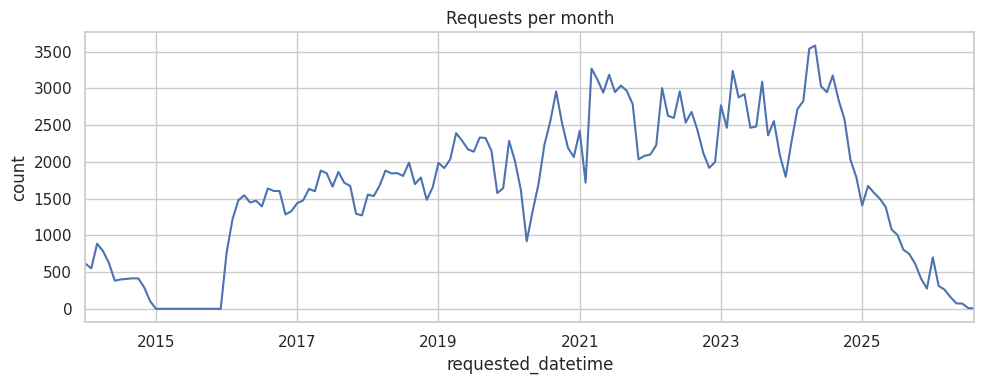

In [9]:
monthly = df.set_index("requested_datetime").resample("MS").size()
plt.figure(figsize=(10, 4))
monthly.plot()
plt.title("Requests per month")
plt.ylabel("count")
plt.tight_layout()
plt.show()

## 6. If your subset has sub-types, compare them

In [10]:
if df[TYPE_COL].nunique() > 1:
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df, y=TYPE_COL, x="log_resolution_hours", showfliers=False)
    plt.title("Log resolution time by request sub-type")
    plt.tight_layout()
    plt.show()
else:
    print("Only one type selected — skip this comparison, or go back and widen CHOSEN_TYPES in notebook 01.")

Only one type selected — skip this comparison, or go back and widen CHOSEN_TYPES in notebook 01.


## Write these down for your report
Fill in your own real observations here once you've run the cells above, e.g.:
- Which factor showed the clearest relationship with resolution time?
- Was the log transform actually justified by the raw-vs-log histograms?
- Any surprising pattern (e.g. a specific zip code or agency being a clear outlier)?
- Does volume have a seasonal pattern that might explain slow periods?

These become your EDA section and directly inform the feature choices in notebook 04.